# 04 · Integración de fuentes externas

Se ejecutan `03_geo_tiempos.py` (coordenadas y matriz de tiempos) y `04_fuentes_externas.py` (precios SIPSA y valor, ONI, consumo FAOSTAT, comercio ICA). Cada sección indica quién usa el archivo.

> Los crudos de SIPSA/FRONTERA (~750 MB) no están en Git. Si `data/raw/SIPSA/` no existe, correr primero `python src/ML_C/00_descargar_datos.py`; las tablas procesadas de `data/clean/` sí están en el repo.

In [1]:
import os, sys
from pathlib import Path
from importlib import import_module

ROOT = Path.cwd().resolve()
while not (ROOT / "config/ML_C/parametros.yaml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src/ML_C"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common import CFG, RAW, CLEAN, RES
from graficos import estilo, COLORES
estilo(); pd.set_option("display.max_columns", 30, "display.width", 160)

In [2]:
import_module("03_geo_tiempos").main()
import_module("04_fuentes_externas").main()

matriz: 1974 filas (esperadas 1974) | huecos: 0
prod promedio: (745, 4) | municipios con producción: 42
  SIPSA: 39 archivos, 294,557 registros, 348 productos, años 2021-2026
  Valor: 37 productos con precio; activos sin precio (11): Arazá, Aromáticas, Cacao, Chontaduro, Flores y follajes, Macadamia, Papachina, Sacha Inchi, Stevia, Sábila, Té
  Ranking por valor: 4 productos cambiarían de grupo
  ONI: fuente ONI_NOAA_CPC (transcripción), años 1998-2025
  FAOSTAT: 69 ítems, años 2020-2023
  Población: PENDIENTE (falta archivo DANE en data/raw/, ver README)
  FRONTERA: 12 archivos -> 15,526 filas agregadas, años 2021-2026


## 1. Coordenadas y matriz de tiempos (Samuel, Alejandro)

In [3]:
mc = pd.read_csv(CLEAN / "municipios_coordenadas.csv", dtype={"cod_dane": str})
dc = pd.read_csv(CLEAN / "destinos_coordenadas.csv")
m = pd.read_csv(CLEAN / "matriz_tiempos.csv", dtype={"origen": str, "destino": str})
print(f"{len(mc)} municipios, {len(dc)} destinos, matriz {len(m)} filas, huecos {m.minutos.isna().sum()}, método {m.metodo.unique()}")
m[m.destino.str.startswith("DEST")].pivot(index="origen", columns="destino", values="minutos").head()

42 municipios, 5 destinos, matriz 1974 filas, huecos 0, método <StringArray>
['aproximado']
Length: 1, dtype: str


destino,DEST_AEROPUERTO_PALMIRA,DEST_BOGOTA,DEST_BUENAVENTURA,DEST_CALI,DEST_MEDELLIN
origen,,,,,
76001,39.5,561.8,139.6,0.0,619.3
76020,265.9,346.1,304.0,303.5,328.8
76036,137.8,437.9,185.0,173.5,447.4
76041,272.1,391.1,284.4,306.9,313.0
76054,251.6,416.7,255.4,285.0,334.5


La matriz es **aproximada** (línea recta × 1,4 a 45 km/h). Mantiene columnas e identificadores, así que se puede reemplazar por OSRM/OSMnx sin cambiar el código de los demás.

## 2. Precios SIPSA y valor de la producción (Samuel)

In [4]:
pp = pd.read_csv(CLEAN / "precio_producto_anual.csv")
tabla = pp.pivot_table(index="producto", columns="anio", values="precio_cop_kg").round(0)
tabla.insert(0, "tipo", pp.groupby("producto")["tipo_precio"].first())
tabla.insert(1, "ámbito", pp.groupby("producto")["ambito"].agg(lambda s: s.mode().iat[0]))
tabla.sort_values(2023, ascending=False)

anio,tipo,ámbito,2021,2022,2023,2024,2025,2026
producto,,,,,,,,
Café,derivado,valle,10914.0,16234.0,20712.0,19520.0,27692.0,31494.0
Pitaya,directo,nacional,8817.0,10289.0,10704.0,11058.0,11184.0,11899.0
Vid,directo,valle,4595.0,6206.0,6824.0,7419.0,8108.0,7828.0
Granadilla,directo,valle,4288.0,6380.0,6720.0,7333.0,7866.0,8034.0
Aguacate,directo,valle,4128.0,5039.0,6183.0,7555.0,7539.0,8785.0
Borojó,directo,nacional,5039.0,6668.0,5918.0,7626.0,6311.0,7297.0
Fresa,directo,valle,4471.0,5195.0,5905.0,7290.0,7506.0,7492.0
Ulluco,directo,valle,2246.0,3645.0,5675.0,2766.0,3300.0,5596.0
Brevo,directo,nacional,4211.0,5569.0,5541.0,5698.0,6150.0,5066.0


- **directo:** precio mayorista SIPSA del mismo producto (promedio de mercados del Valle; si no hay, mediana nacional).
- **derivado:** el producto en finca no se cotiza en SIPSA y se aproxima desde el procesado con un factor físico (caña de azúcar ← azúcar, caña panelera ← panela, café pergamino ← café molido). Son aproximaciones y sobreestiman el valor en finca (ver `limitaciones_pronostico.md`).

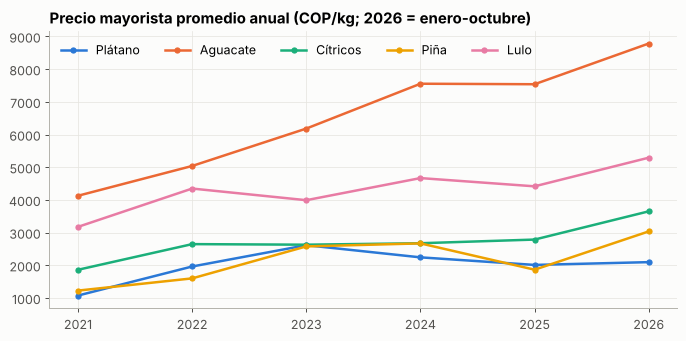

In [5]:
fig, ax = plt.subplots()
for i, p in enumerate(["Plátano", "Aguacate", "Cítricos", "Piña", "Lulo"]):
    s = pp[pp.producto == p].set_index("anio")["precio_cop_kg"]
    ax.plot(s.index, s.values, marker="o", ms=4, color=COLORES[i], label=p)
ax.set_title("Precio mayorista promedio anual (COP/kg; 2026 = enero-octubre)"); ax.legend(ncol=5, loc="upper left")
plt.show()

In [6]:
r = pd.read_csv(RES / "ranking_valor_vs_toneladas.csv")
print("Productos que cambiarían de grupo si el ranking fuera por valor:")
r[r.cambia][["producto", "estado", "ranking_toneladas", "ranking_valor", "valor_cop_2019_2023"]]

Productos que cambiarían de grupo si el ranking fuera por valor:


,producto,estado,ranking_toneladas,ranking_valor,valor_cop_2019_2023
17,Granadilla,simplificado,24,18.0,7.814765e+10
21,Pitaya,simplificado,29,22.0,4.269698e+10
22,Cebolla Larga,detallado,20,23.0,4.134574e+10
33,Sábila,detallado,21,NaN,NaN


In [7]:
v = pd.read_csv(CLEAN / "valor_producto.csv", dtype={"cod_dane": str})
w = v[v.anio.between(2019, 2023)].groupby("producto")[["produccion_t", "valor_cop"]].sum()
w = (w / w.sum() * 100).round(1).sort_values("valor_cop", ascending=False).head(10)
w.columns = ["% toneladas", "% valor"]; w

,% toneladas,% valor
producto,,
Caña de azúcar,95.2,76.6
Café,0.2,5.9
Plátano,1.2,4.3
Aguacate,0.3,2.9
Cítricos,0.6,2.8
Piña,0.6,2.0
Caña panelera,1.2,1.0
Vid,0.1,0.9
Banano,0.3,0.8


## 3. ONI (modelo LightGBM)

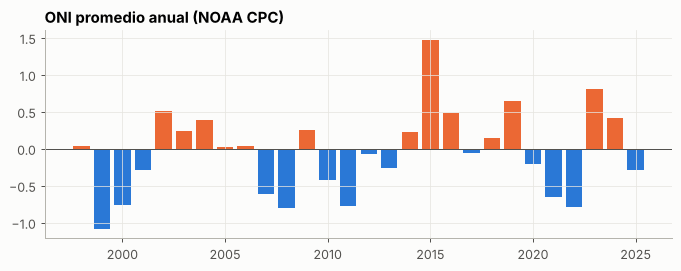

,anio,oni,n_estaciones,oni_max,oni_min,fase
20,2018,0.142,12,1.05,-0.71,neutral
21,2019,0.649,12,0.99,0.20,Niño
22,2020,-0.211,12,0.71,-1.11,neutral
23,2021,-0.651,12,-0.31,-0.99,Niña
24,2022,-0.783,12,-0.68,-0.89,Niña
25,2023,0.814,12,1.99,-0.55,Niño
26,2024,0.410,12,1.84,-0.43,neutral
27,2025,-0.282,12,0.02,-0.61,neutral


In [8]:
oni = pd.read_csv(CLEAN / "oni.csv")
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(oni.anio, oni.oni, color=np.where(oni.oni >= 0, COLORES[1], COLORES[0]), width=0.8)
ax.axhline(0, color="#52514e", lw=0.8); ax.set_title("ONI promedio anual (NOAA CPC)"); plt.show()
oni.tail(8)

## 4. Consumo per cápita FAOSTAT (Samuel, excedentes)

In [9]:
c = pd.read_csv(CLEAN / "consumo_percapita.csv")
c.pivot_table(index="item_faostat", columns="anio", values="kg_per_capita_anio").sort_values(2023, ascending=False).head(15)

anio,2020,2021,2022,2023
item_faostat,,,,
"Fruits, other",57.02,59.52,60.88,60.26
Potatoes and products,55.68,57.93,57.33,56.95
Maize and products,43.15,46.18,50.58,51.15
Vegetables,51.75,50.71,51.83,51.00
Rice and products,56.32,43.34,46.60,46.54
Beer,39.41,48.97,46.40,46.28
Plantains,33.57,33.53,35.68,37.18
Wheat and products,34.28,34.79,37.09,36.64
Sugar (Raw Equivalent),31.73,32.01,29.36,29.56


## 5. Comercio ICA en frontera (Samuel, respaldo de la mezcla nacional/exportación)

In [10]:
ci = pd.read_csv(CLEAN / "comercio_ica_frontera.csv")
ex = ci[(ci.tipo_comercio == "EXPORTACIONES") & ci.puerto.str.contains("Buenaventura|Palmira", na=False)]
ex.pivot_table(index="producto_ica", columns="anio", values="toneladas", aggfunc="sum").fillna(0).round(0).sort_values(2024, ascending=False).head(12)

anio,2021,2022,2023,2024,2025,2026
producto_ica,,,,,,
CAFE,215776.0,212284.0,225818.0,291066.0,296169.0,191509.0
PALMA DE ACEITE,0.0,0.0,0.0,4320.0,0.0,0.0
LIMA ACIDA TAHITI,899.0,548.0,1038.0,1049.0,171.0,38.0
ALGODON,0.0,0.0,0.0,644.0,0.0,161.0
PAPAYA,0.0,0.0,0.0,575.0,178.0,53.0
MAIZ,5326.0,5972.0,51072.0,569.0,708.0,252.0
AGUACATE HASS,978.0,454.0,2640.0,491.0,139.0,24.0
PINO PATULA MADERA,0.0,0.0,0.0,300.0,1050.0,0.0
"AJI, PIMENTÓN, PIMIENTO",191.0,121.0,102.0,241.0,103.0,65.0


## 6. Población municipal (pendiente)

No se encontró el archivo de proyecciones del DANE en `data/raw/`. Cuando se descargue (ver README), `04_fuentes_externas.py` genera `poblacion_municipal.csv` sin cambiar nada más.